# Fuzzy C-Means + PCA pada Dataset Student Performance (`student-mat.csv`)

**Tujuan**
- **PCA**: reduksi dimensi sekaligus visualisasi data.
- **FCM (Fuzzy C-Means)**: mengelompokkan siswa berdasarkan fitur yang dipilih.
- **Evaluasi** (hanya tiga metrik):
  1. **Silhouette score**: kualitas cluster secara umum (kohesi vs separasi).
  2. **Partition Coefficient (PC)**: evaluasi khusus FCM, mengukur ketegasan partisi fuzzy.
  3. **Explained variance ratio**: evaluasi khusus PCA, mengukur informasi yang dipertahankan setelah reduksi.
- **Perbandingan**: FCM + PCA vs FCM saja (tanpa PCA), baik dari sisi metrik maupun waktu eksekusi.

**Alur**: Load data → Seleksi & standardisasi fitur → PCA (explained variance) → Pemilihan jumlah cluster → FCM + PCA vs FCM saja → Evaluasi (Silhouette, PC) → Waktu eksekusi → Visualisasi → Profil cluster → Kesimpulan.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ====== PARAMETER (silakan diubah) ======
CSV_PATH      = "student-mat.csv"   # path file dataset
M_FUZZ        = 1.5                 # fuzzifier FCM (m > 1). m=2 menghasilkan solusi degenerat pada data ini (lihat catatan)
MAX_ITER      = 500
TOL           = 1e-5
N_INIT        = 5                   # jumlah inisialisasi acak FCM (diambil yang J terkecil)
K_RANGE       = range(2, 9)         # kandidat jumlah cluster
VAR_THRESHOLD = 0.80                # target kumulatif explained variance untuk memilih n_komponen PCA
N_REPEAT_TIME = 20                  # pengulangan untuk pengukuran waktu
SEED          = 42

## 1. Load Data

In [2]:
df = pd.read_csv(CSV_PATH, sep=";")
# G1 & G2 terbaca sebagai string (tanda kutip pada file) -> ubah ke numerik
for c in ["G1", "G2", "G3"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Ukuran data :", df.shape)
print("Missing     :", int(df.isna().sum().sum()))
df.head()

Ukuran data : (395, 33)
Missing     : 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Pemilihan Fitur dan Standardisasi

Fitur yang dipilih adalah seluruh fitur **numerik** (kategorikal seperti `school`, `sex`, `Mjob`, dll. tidak dipakai karena FCM/PCA berbasis jarak Euclidean).
Daftar `FEATURES` dapat diubah bila ingin memakai subset fitur lain.

Standardisasi (z-score) **wajib** karena PCA dan FCM sensitif terhadap skala (mis. `absences` berskala 0–75, `famrel` 1–5).

In [3]:
FEATURES = ["age", "Medu", "Fedu", "traveltime", "studytime", "failures",
            "famrel", "freetime", "goout", "Dalc", "Walc", "health",
            "absences", "G1", "G2", "G3"]

X_raw = df[FEATURES].astype(float).values
X = StandardScaler().fit_transform(X_raw)
print("Jumlah sampel :", X.shape[0])
print("Jumlah fitur  :", X.shape[1])

Jumlah sampel : 395
Jumlah fitur  : 16


## 3. Implementasi Fuzzy C-Means (NumPy)

Fungsi objektif: $J_m=\sum_{i=1}^{N}\sum_{j=1}^{c} u_{ij}^m \, \|x_i - v_j\|^2$

Update pusat: $v_j=\dfrac{\sum_i u_{ij}^m x_i}{\sum_i u_{ij}^m}$  
Update keanggotaan: $u_{ij}=\dfrac{1}{\sum_{k=1}^{c}\left(\dfrac{d_{ij}}{d_{ik}}\right)^{2/(m-1)}}$

Label tegas (hard label) untuk metrik evaluasi diambil dari `argmax` derajat keanggotaan.

Evaluasi FCM (Partition Coefficient): $PC=\dfrac{1}{N}\sum_{i=1}^{N}\sum_{j=1}^{c} u_{ij}^2$, bernilai $1/c \le PC \le 1$ (semakin mendekati 1 semakin tegas partisinya).

In [4]:
def _dist(X, V):
    # jarak Euclidean (N x c) secara vectorized
    d2 = (X**2).sum(1)[:, None] - 2 * X @ V.T + (V**2).sum(1)[None, :]
    return np.sqrt(np.maximum(d2, 1e-12))

def fcm_single(X, c, m=2.0, max_iter=300, tol=1e-5, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    N = X.shape[0]
    U = rng.random((N, c))
    U /= U.sum(1, keepdims=True)
    for it in range(1, max_iter + 1):
        U_old = U
        Um = U ** m
        V = (Um.T @ X) / Um.sum(0)[:, None]
        D = _dist(X, V)
        inv = D ** (-2.0 / (m - 1))
        U = inv / inv.sum(1, keepdims=True)
        delta = np.abs(U - U_old).max()      # konvergensi: perubahan maksimum keanggotaan
        if delta < tol:
            break
    J = ((U ** m) * _dist(X, V) ** 2).sum()
    return U, V, J, it

def fcm(X, c, m=2.0, max_iter=300, tol=1e-5, n_init=5, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        res = fcm_single(X, c, m, max_iter, tol, rng)
        if best is None or res[2] < best[2]:
            best = res
    U, V, J, n_it = best
    return {"U": U, "centers": V, "J": J, "n_iter": n_it, "labels": U.argmax(1)}

def partition_coefficient(U):
    return (U ** 2).sum() / U.shape[0]   # Partition Coefficient (PC), rentang 1/c .. 1

def is_degenerate(U, tol=1e-3):
    # solusi trivial: semua keanggotaan ~ 1/c (pusat cluster menyatu) -> PC == 1/c
    return partition_coefficient(U) < 1.0 / U.shape[1] + tol

> **Catatan penting tentang fuzzifier `m`.** Pada data dengan struktur cluster lemah (seperti data survei siswa ini), FCM dengan `m = 2` cenderung konvergen ke **solusi trivial**: semua pusat cluster menyatu di rata-rata data dan setiap titik memiliki keanggotaan sama (1/c). Gejalanya: Partition Coefficient (PC) tepat sama dengan 1/c dan skor Silhouette identik untuk berbagai k. Karena itu default dipakai `m = 1.5`. Sel di bawah memeriksa kondisi ini otomatis.

## 4. PCA: Explained Variance (Validasi Reduksi)

Explained variance ratio menunjukkan berapa banyak informasi (varians) data asli yang dipertahankan oleh tiap komponen utama.
Jumlah komponen untuk klasterisasi dipilih sebagai jumlah minimum yang mencapai kumulatif ≥ `VAR_THRESHOLD`.

> Inilah **evaluasi PCA** yang dipakai pada notebook ini: *explained variance ratio* (per komponen dan kumulatif).

,PC,Explained variance ratio,Kumulatif
0,PC1,0.2122,0.2122
1,PC2,0.1308,0.3430
2,PC3,0.0974,0.4404
3,PC4,0.0800,0.5203
4,PC5,0.0731,0.5934
5,PC6,0.0633,0.6567
6,PC7,0.0582,0.7149
7,PC8,0.0562,0.7710
8,PC9,0.0481,0.8192
9,PC10,0.0448,0.8640


Jumlah komponen terpilih (kumulatif >= 80%) : 9
Total variance yang dipertahankan                       : 81.92%
Variance yang dipertahankan oleh PC1+PC2 (visualisasi 2D): 34.30%


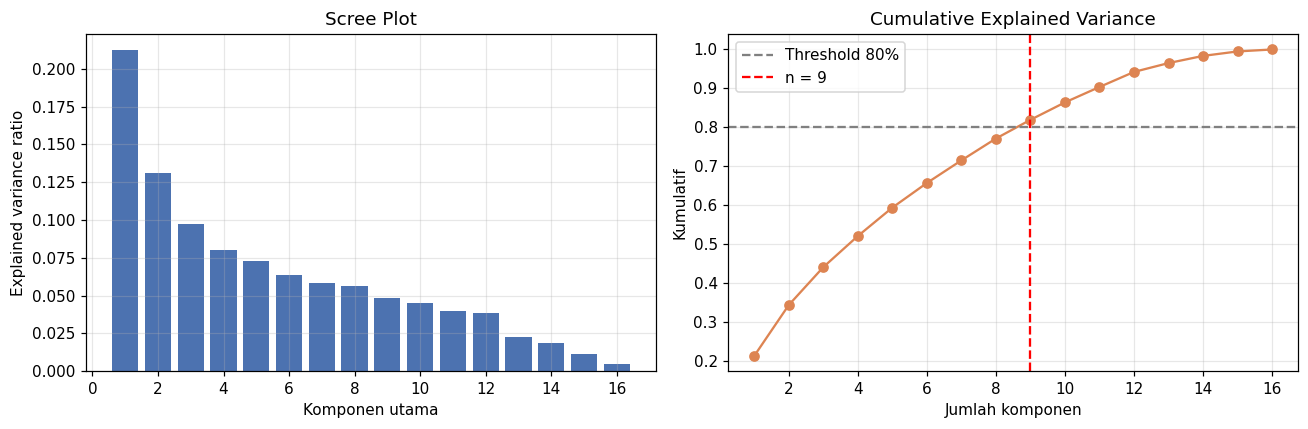

In [5]:
pca_full = PCA(random_state=SEED).fit(X)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
N_COMP = int(np.argmax(cum >= VAR_THRESHOLD) + 1)

evr_table = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(evr))],
    "Explained variance ratio": evr,
    "Kumulatif": cum,
})
display(evr_table.round(4))
print(f"Jumlah komponen terpilih (kumulatif >= {VAR_THRESHOLD:.0%}) : {N_COMP}")
print(f"Total variance yang dipertahankan                       : {cum[N_COMP-1]:.2%}")
print(f"Variance yang dipertahankan oleh PC1+PC2 (visualisasi 2D): {cum[1]:.2%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(evr)+1), evr, color="#4C72B0")
ax[0].set(title="Scree Plot", xlabel="Komponen utama", ylabel="Explained variance ratio")
ax[1].plot(range(1, len(cum)+1), cum, marker="o", color="#DD8452")
ax[1].axhline(VAR_THRESHOLD, ls="--", color="gray", label=f"Threshold {VAR_THRESHOLD:.0%}")
ax[1].axvline(N_COMP, ls="--", color="red", label=f"n = {N_COMP}")
ax[1].set(title="Cumulative Explained Variance", xlabel="Jumlah komponen", ylabel="Kumulatif")
ax[1].legend()
plt.tight_layout(); plt.show()

In [6]:
# Kontribusi fitur (loading) pada PC1 & PC2 untuk interpretasi sumbu visualisasi
loadings = pd.DataFrame(pca_full.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
loadings.round(3).sort_values("PC1", key=np.abs, ascending=False)

,PC1,PC2
G2,0.468,0.170
G3,0.453,0.195
G1,0.451,0.150
failures,-0.318,0.003
Medu,0.230,0.213
Fedu,0.208,0.197
Walc,-0.191,0.519
Dalc,-0.167,0.500
age,-0.166,0.067
goout,-0.166,0.375


In [7]:
pca = PCA(n_components=N_COMP, random_state=SEED)
X_pca = pca.fit_transform(X)          # ruang untuk FCM + PCA
X_vis = PCA(n_components=2, random_state=SEED).fit_transform(X)   # ruang 2D untuk visualisasi
print("Bentuk data setelah PCA:", X_pca.shape)

Bentuk data setelah PCA: (395, 9)


## 5. Pemilihan Jumlah Cluster (k)

Untuk tiap kandidat `k`, FCM dijalankan pada kedua skenario. Dua metrik dihitung:
- **Silhouette score** (metrik utama pemilih `k`): semakin **tinggi** semakin baik.
- **Partition Coefficient (PC)**: semakin **tinggi** semakin tegas partisinya. PC secara alami turun saat `k` naik (batas bawahnya `1/k`), sehingga PC **tidak** dipakai untuk memilih `k`, hanya untuk menilai ketegasan partisi pada `k` terpilih.

,Sil (FCM+PCA),PC (FCM+PCA),Sil (FCM saja),PC (FCM saja)
k,,,,
2,0.1551,0.6142,0.1258,0.5456
3,0.0810,0.4306,0.0503,0.3696
4,0.1034,0.3549,0.0493,0.2799
5,0.0693,0.2980,-0.0596,0.2251
6,0.0051,0.2541,-0.1488,0.1882
7,-0.0335,0.2221,-0.0919,0.1617
8,-0.0248,0.1980,-0.1649,0.1421


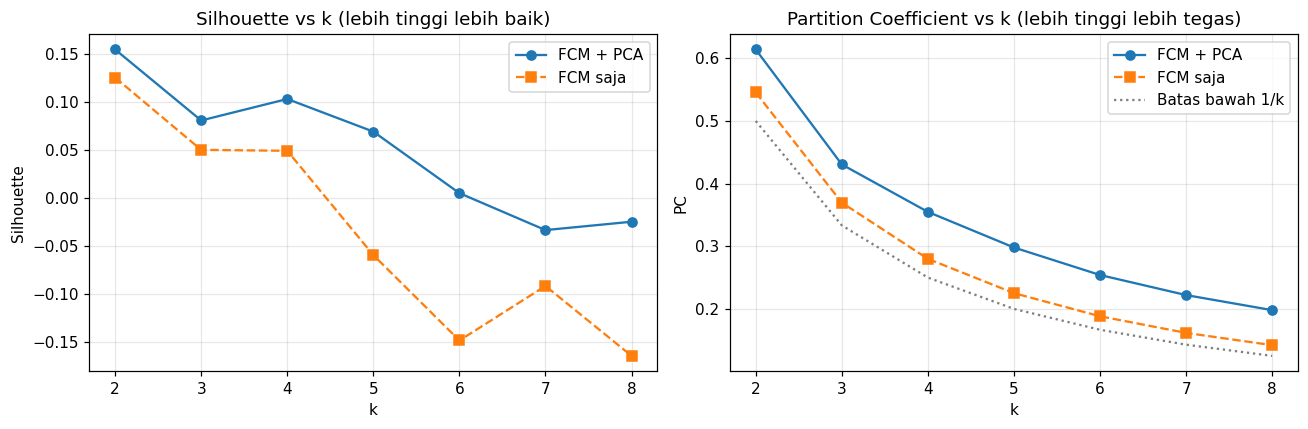

k terpilih (Silhouette tertinggi, FCM + PCA) = 2


In [8]:
rows = []
for k in K_RANGE:
    r_p = fcm(X_pca, k, M_FUZZ, MAX_ITER, TOL, N_INIT, SEED)
    r_f = fcm(X,     k, M_FUZZ, MAX_ITER, TOL, N_INIT, SEED)
    for nm, r in (("FCM+PCA", r_p), ("FCM saja", r_f)):
        if is_degenerate(r["U"]):
            print(f"[PERINGATAN] k={k}, {nm}: solusi degenerat (PC = 1/c). Turunkan M_FUZZ.")
    rows.append({
        "k": k,
        "Sil (FCM+PCA)": silhouette_score(X_pca, r_p["labels"]),
        "PC (FCM+PCA)": partition_coefficient(r_p["U"]),
        "Sil (FCM saja)": silhouette_score(X, r_f["labels"]),
        "PC (FCM saja)": partition_coefficient(r_f["U"]),
    })
k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_table.index, k_table["Sil (FCM+PCA)"], "o-", label="FCM + PCA")
ax[0].plot(k_table.index, k_table["Sil (FCM saja)"], "s--", label="FCM saja")
ax[0].set(title="Silhouette vs k (lebih tinggi lebih baik)", xlabel="k", ylabel="Silhouette"); ax[0].legend()
ax[1].plot(k_table.index, k_table["PC (FCM+PCA)"], "o-", label="FCM + PCA")
ax[1].plot(k_table.index, k_table["PC (FCM saja)"], "s--", label="FCM saja")
ax[1].plot(k_table.index, 1.0 / k_table.index.values, ":", color="gray", label="Batas bawah 1/k")
ax[1].set(title="Partition Coefficient vs k (lebih tinggi lebih tegas)", xlabel="k", ylabel="PC"); ax[1].legend()
plt.tight_layout(); plt.show()

# k dipilih berdasarkan Silhouette (metrik utama) pada skenario FCM + PCA
K_BEST = int(k_table["Sil (FCM+PCA)"].idxmax())
print("k terpilih (Silhouette tertinggi, FCM + PCA) =", K_BEST)

## 6. Klasterisasi Final: FCM + PCA vs FCM Saja

Kedua skenario memakai `k`, `m`, dan pengaturan inisialisasi yang sama agar perbandingan adil.

> **Catatan metrik**: Silhouette bergantung pada ruang fitur tempat jarak dihitung. Karena itu Silhouette dihitung dua kali:
> 1. **Ruang masing-masing** (FCM+PCA di ruang PCA, FCM saja di ruang fitur asli ter-standardisasi), dan
> 2. **Ruang bersama** (label FCM+PCA dievaluasi di ruang fitur asli ter-standardisasi) sebagai pembanding yang setara.
>
> **Partition Coefficient** dihitung dari matriks keanggotaan `U` masing-masing skenario, sedangkan **explained variance ratio** hanya berlaku untuk skenario yang memakai PCA.

In [9]:
res_pca = fcm(X_pca, K_BEST, M_FUZZ, MAX_ITER, TOL, N_INIT, SEED)
res_raw = fcm(X,     K_BEST, M_FUZZ, MAX_ITER, TOL, N_INIT, SEED)

# --- Evaluasi 1: Silhouette score
sil_p  = silhouette_score(X_pca, res_pca["labels"])     # ruang PCA
sil_r  = silhouette_score(X,     res_raw["labels"])     # ruang asli
sil_pc = silhouette_score(X,     res_pca["labels"])     # label FCM+PCA dievaluasi di ruang asli

# --- Evaluasi 2 (khusus FCM): Partition Coefficient
pc_p = partition_coefficient(res_pca["U"])
pc_r = partition_coefficient(res_raw["U"])

comp = pd.DataFrame({
    "FCM + PCA (ruang PCA)": [sil_p, pc_p, res_pca["n_iter"], X_pca.shape[1]],
    "FCM saja (ruang asli)": [sil_r, pc_r, res_raw["n_iter"], X.shape[1]],
    "FCM + PCA (dievaluasi di ruang asli)": [sil_pc, pc_p, res_pca["n_iter"], X.shape[1]],
}, index=["Silhouette score (↑)", "Partition Coefficient (↑)", "Iterasi konvergen", "Dimensi fitur"])
display(comp.round(4))
print(f"Batas bawah PC (1/k) untuk k={K_BEST}: {1.0 / K_BEST:.4f}")
print("Degenerat? FCM+PCA:", is_degenerate(res_pca["U"]), "| FCM saja:", is_degenerate(res_raw["U"]))

# --- Evaluasi 3 (khusus PCA): Explained variance ratio
pca_eval = pd.DataFrame({
    "Nilai": [pca.explained_variance_ratio_.sum(), cum[1]],
}, index=[f"Explained variance ratio total ({N_COMP} komponen, dipakai FCM)", "Explained variance ratio PC1+PC2 (visualisasi 2D)"])
display(pca_eval.round(4))

,FCM + PCA (ruang PCA),FCM saja (ruang asli),FCM + PCA (dievaluasi di ruang asli)
Silhouette score (↑),0.1551,0.1258,0.1302
Partition Coefficient (↑),0.6142,0.5456,0.6142
Iterasi konvergen,32.0000,58.0000,32.0000
Dimensi fitur,9.0000,16.0000,16.0000


Batas bawah PC (1/k) untuk k=2: 0.5000
Degenerat? FCM+PCA: False | FCM saja: False


,Nilai
"Explained variance ratio total (9 komponen, dipakai FCM)",0.8192
Explained variance ratio PC1+PC2 (visualisasi 2D),0.3430


## 7. Perbandingan Waktu Eksekusi

,Rata-rata (detik),Std (detik)
PCA (transformasi),0.00158,0.00015
FCM di ruang PCA,0.04077,0.00439
TOTAL FCM + PCA,0.04235,0.00447
FCM saja (tanpa PCA),0.08323,0.01078


Rasio waktu (FCM saja / FCM+PCA total): 1.97x -> FCM+PCA lebih cepat
Rasio waktu FCM murni (ruang asli / ruang PCA): 2.04x


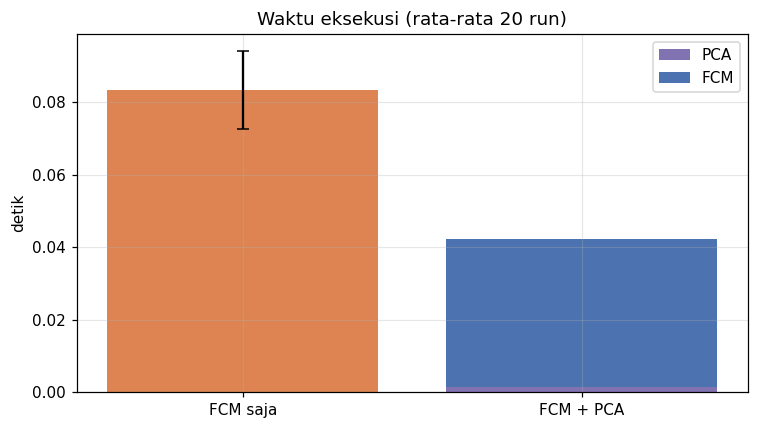

In [10]:
def run_pca_fcm(seed):
    t0 = time.perf_counter()
    Z = PCA(n_components=N_COMP, random_state=SEED).fit_transform(X)
    t1 = time.perf_counter()
    fcm(Z, K_BEST, M_FUZZ, MAX_ITER, TOL, N_INIT, seed)
    t2 = time.perf_counter()
    return t1 - t0, t2 - t1, t2 - t0

def run_fcm_only(seed):
    t0 = time.perf_counter()
    fcm(X, K_BEST, M_FUZZ, MAX_ITER, TOL, N_INIT, seed)
    return time.perf_counter() - t0

# warm-up agar waktu pertama (import/cache) tidak mengganggu
run_pca_fcm(0); run_fcm_only(0)

t_pca, t_fcm_p, t_tot_p, t_raw = [], [], [], []
for s in range(N_REPEAT_TIME):
    a, b, c = run_pca_fcm(s); t_pca.append(a); t_fcm_p.append(b); t_tot_p.append(c)
    t_raw.append(run_fcm_only(s))

time_df = pd.DataFrame({
    "Rata-rata (detik)": [np.mean(t_pca), np.mean(t_fcm_p), np.mean(t_tot_p), np.mean(t_raw)],
    "Std (detik)":       [np.std(t_pca),  np.std(t_fcm_p),  np.std(t_tot_p),  np.std(t_raw)],
}, index=["PCA (transformasi)", "FCM di ruang PCA", "TOTAL FCM + PCA", "FCM saja (tanpa PCA)"])
display(time_df.round(5))

speedup = np.mean(t_raw) / np.mean(t_tot_p)
print(f"Rasio waktu (FCM saja / FCM+PCA total): {speedup:.2f}x "
      f"-> {'FCM+PCA lebih cepat' if speedup > 1 else 'FCM saja lebih cepat'}")
print(f"Rasio waktu FCM murni (ruang asli / ruang PCA): {np.mean(t_raw)/np.mean(t_fcm_p):.2f}x")

fig, ax = plt.subplots(figsize=(7, 4))
labels_t = ["FCM saja", "FCM + PCA"]
ax.bar(labels_t[0], np.mean(t_raw), yerr=np.std(t_raw), color="#DD8452", capsize=4)
ax.bar(labels_t[1], np.mean(t_pca), color="#8172B2", label="PCA")
ax.bar(labels_t[1], np.mean(t_fcm_p), bottom=np.mean(t_pca), color="#4C72B0", label="FCM")
ax.set(title=f"Waktu eksekusi (rata-rata {N_REPEAT_TIME} run)", ylabel="detik"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Visualisasi Cluster di Ruang PCA 2D

Kedua hasil klasterisasi diproyeksikan ke PC1–PC2 yang sama sehingga dapat dibandingkan secara visual. Titik hitam bukan "pusat" asli untuk FCM saja; pusat diproyeksikan menggunakan transformasi PCA 2D.

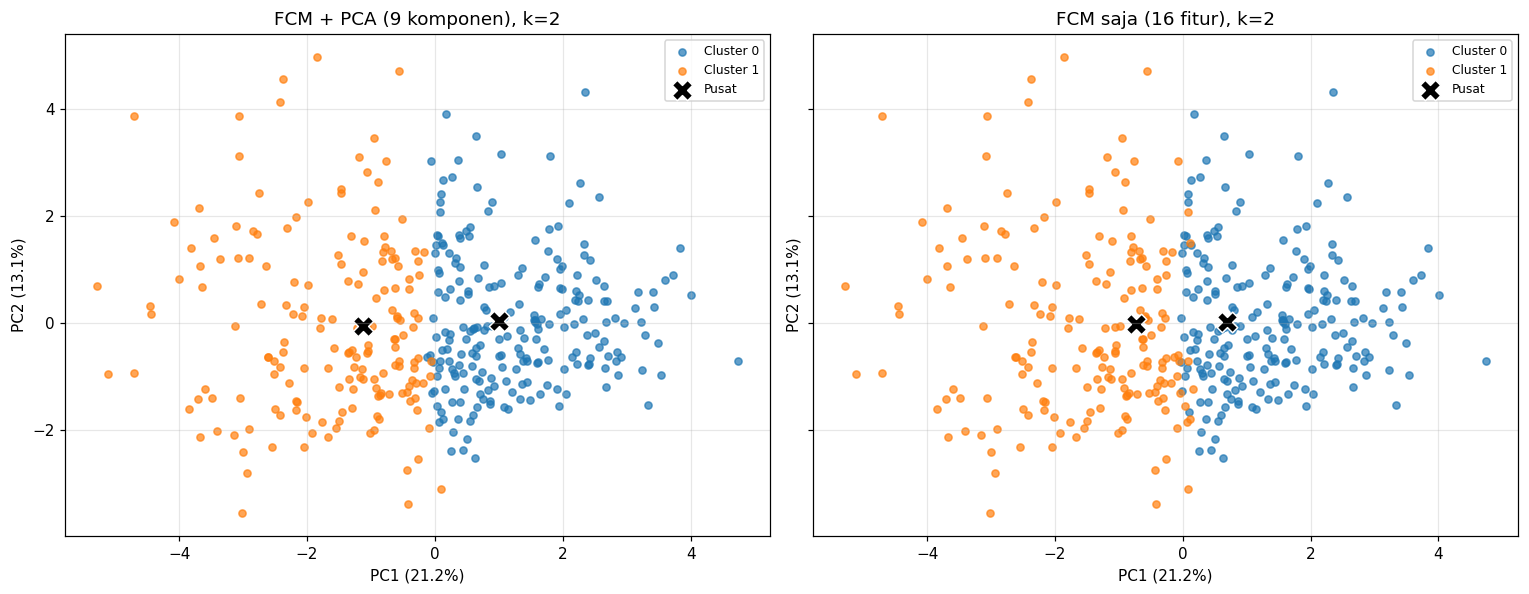

In [11]:
pca2 = PCA(n_components=2, random_state=SEED).fit(X)
ev2 = pca2.explained_variance_ratio_
cmap = plt.get_cmap("tab10")

def scatter(ax, labels, title, centers_std):
    for k in range(K_BEST):
        pts = X_vis[labels == k]
        ax.scatter(pts[:, 0], pts[:, 1], s=22, alpha=0.7, color=cmap(k), label=f"Cluster {k}")
    cv = pca2.transform(centers_std)
    ax.scatter(cv[:, 0], cv[:, 1], marker="X", s=180, c="black", edgecolor="white", label="Pusat")
    ax.set(title=title, xlabel=f"PC1 ({ev2[0]:.1%})", ylabel=f"PC2 ({ev2[1]:.1%})")
    ax.legend(fontsize=8)

# pusat FCM+PCA dikembalikan ke ruang standar lalu diproyeksikan; untuk 2D langsung pakai komponen terpilih
centers_pca_std = pca.inverse_transform(res_pca["centers"])
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
scatter(ax[0], res_pca["labels"], f"FCM + PCA ({N_COMP} komponen), k={K_BEST}", centers_pca_std)
scatter(ax[1], res_raw["labels"], f"FCM saja ({X.shape[1]} fitur), k={K_BEST}", res_raw["centers"])
plt.tight_layout(); plt.show()

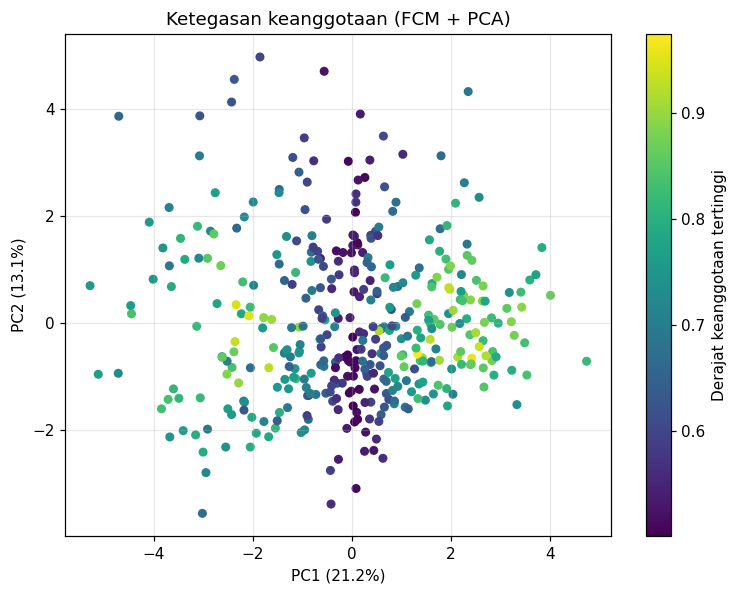

In [12]:
# Visualisasi derajat keanggotaan (fuzzy): sebar PC1-PC2 diwarnai oleh keanggotaan tertinggi
fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(X_vis[:, 0], X_vis[:, 1], c=res_pca["U"].max(1), cmap="viridis", s=24)
plt.colorbar(sc, label="Derajat keanggotaan tertinggi")
ax.set(title="Ketegasan keanggotaan (FCM + PCA)", xlabel=f"PC1 ({ev2[0]:.1%})", ylabel=f"PC2 ({ev2[1]:.1%})")
plt.tight_layout(); plt.show()

## 9. Profil Cluster (FCM + PCA)

Rata-rata fitur asli per cluster untuk membantu interpretasi.

In [13]:
prof = df[FEATURES].copy()
prof["cluster"] = res_pca["labels"]
profile = prof.groupby("cluster").mean().round(2)
profile.insert(0, "jumlah_siswa", prof["cluster"].value_counts().sort_index())
display(profile.T)

cluster,0,1
jumlah_siswa,222.00,173.00
age,16.45,17.02
Medu,3.08,2.33
Fedu,2.84,2.11
traveltime,1.33,1.60
studytime,2.18,1.86
failures,0.06,0.68
famrel,3.96,3.92
freetime,3.14,3.35
goout,2.91,3.37


## 10. Ringkasan Perbandingan

In [14]:
summary = pd.DataFrame({
    "FCM + PCA": [sil_p, sil_pc, pc_p, np.mean(t_tot_p), X_pca.shape[1]],
    "FCM saja":  [sil_r, sil_r,  pc_r, np.mean(t_raw),   X.shape[1]],
}, index=["Silhouette (ruang masing-masing)", "Silhouette (ruang asli, setara)",
          "Partition Coefficient", "Waktu rata-rata (detik)", "Dimensi"])
display(summary.round(5))

better_sil = "FCM + PCA" if sil_p > sil_r else "FCM saja"
better_sil_eq = "FCM + PCA" if sil_pc > sil_r else "FCM saja"
better_pc  = "FCM + PCA" if pc_p > pc_r else "FCM saja"
faster     = "FCM + PCA" if np.mean(t_tot_p) < np.mean(t_raw) else "FCM saja"
print(f"- Silhouette (ruang masing-masing) lebih baik : {better_sil}")
print(f"- Silhouette (ruang asli, setara) lebih baik  : {better_sil_eq}")
print(f"- Partition Coefficient lebih tinggi          : {better_pc}")
print(f"- Waktu eksekusi lebih cepat                  : {faster}")
print(f"- PCA mempertahankan {pca.explained_variance_ratio_.sum():.1%} varians dengan {N_COMP} dari {X.shape[1]} fitur.")

,FCM + PCA,FCM saja
Silhouette (ruang masing-masing),0.15514,0.12579
"Silhouette (ruang asli, setara)",0.13022,0.12579
Partition Coefficient,0.61416,0.54555
Waktu rata-rata (detik),0.04235,0.08323
Dimensi,9.00000,16.00000


- Silhouette (ruang masing-masing) lebih baik : FCM + PCA
- Silhouette (ruang asli, setara) lebih baik  : FCM + PCA
- Partition Coefficient lebih tinggi          : FCM + PCA
- Waktu eksekusi lebih cepat                  : FCM + PCA
- PCA mempertahankan 81.9% varians dengan 9 dari 16 fitur.


### Catatan Interpretasi
- **Silhouette score** (rentang −1 s.d. 1): semakin tinggi, cluster semakin kompak dan terpisah. Nilai rendah (< 0,25) menandakan struktur cluster pada data ini lemah/tumpang tindih; ini karakteristik data, bukan kesalahan implementasi. Karena dihitung pada ruang fitur tertentu, gunakan kolom *ruang asli* untuk perbandingan yang setara antara FCM + PCA dan FCM saja.
- **Partition Coefficient (PC)** (rentang 1/c s.d. 1): PC mendekati 1 berarti keanggotaan tiap titik tegas pada satu cluster, sedangkan PC mendekati 1/c berarti keanggotaan menyebar merata (partisi sangat fuzzy atau solusi degenerat). PC hanya menilai ketegasan partisi dan tidak menilai apakah cluster-nya bermakna, jadi dibaca bersama Silhouette.
- **Explained variance ratio** (khusus PCA): memvalidasi reduksi; semakin besar kumulatif varians yang tertahan, semakin kecil informasi yang hilang saat dimensi dikurangi.
- **Waktu eksekusi**: pada dataset kecil (395 × 16) selisih waktu sangat kecil (milidetik). Reduksi dimensi tidak otomatis mempercepat FCM: waktu FCM bergantung pada jumlah iterasi hingga konvergen, bukan hanya jumlah dimensi (lihat baris *Iterasi konvergen*), dan PCA menambah biaya transformasi. Keuntungan kecepatan PCA lebih terlihat pada data berdimensi/berukuran besar.
- Hasil bergantung pada inisialisasi acak, `m`, dan pilihan fitur; ubah parameter di sel konfigurasi untuk eksperimen lanjutan.